# PHASE 1: Business Understanding, Data Understanding & Preparation (CRISP-DM)
**Assigned Fictional Company:** G-Yan! (*FinTech Startup Track*)  
**Methodology:** [CRISP-DM (Cross-Industry Standard Process for Data Mining)](https://www.datascience-pm.com/crisp-dm-2/)  
**Dataset:** [UCI Default of Credit Card Clients Dataset (ID #350)](https://archive.ics.uci.edu/ml/datasets/default+of+credit+card+clients) | [Kaggle Mirror](https://www.kaggle.com/datasets/uciml/default-of-credit-card-clients-dataset)  
**Primary Literature:** [Yeh, I. C., & Lien, C. H. (2009), *Expert Systems with Applications*, 36(2), 2473–2480](https://doi.org/10.1016/j.eswa.2007.12.020)  
**Statistical Audit Reference:** [Jose M Sallan (2023) — Cleaning the Credit Card Defaults Dataset](https://jmsallan.netlify.app/blog/cleaning-the-credit-card-defaults-dataset/)

---

## 1. Business Problem, Hypotheses & Objectives

### 1.1 Operational Context & Core Business Problem
**G-Yan!** is a digital consumer lending and virtual revolving credit card startup serving retail cardholders. While rapid customer onboarding has expanded the active portfolio, portfolio audits across a benchmark cohort of **30,000 cardholders** tracked from April to September 2005 ([UCI Default of Credit Card Clients Dataset](https://archive.ics.uci.edu/ml/datasets/default+of+credit+card+clients)) reveal that **6,636 clients (22.12%) defaulted** on their subsequent month's payment, compared to **23,364 non-defaulting clients (77.88%)**.

Currently, G-Yan! relies on static credit bureau cutoffs at account origination rather than dynamic monthly behavioral monitoring. Management needs an automated, reproducible data preprocessing and risk-scoring pipeline that ingests 6-month longitudinal billing and payment histories to flag high-risk accounts **30 days prior to default**.

### 1.2 Research Questions & Testable Hypotheses
Grounded in empirical credit risk benchmarks ([TechRxiv Credit Card Default Study](https://www.techrxiv.org/doi/pdf/10.36227/techrxiv.176720000.07292428); [Vineet416 UCI Benchmark Analysis](https://github.com/vineet416/Credit_Card_Default_Prediction)), we establish three research questions and formal statistical hypotheses:

1. **RQ1 (Repayment Delinquency Dynamics):** How strongly do recent monthly repayment status delays (`PAY_0` through `PAY_6`) differentiate cardholders who default next month from those who pay duly?
   * $H_{0,1}$: Next-month default probability is independent of prior repayment delay status ($\chi^2$ test $p \ge 0.05$).
   * $H_{1,1}$: Cardholders with a repayment delay of $\ge 2$ months in September (`PAY_0 >= 2`) exhibit a significantly higher default rate than clients paying on time (**69.6% vs. 13.8%**).
2. **RQ2 (Credit Limit Tier & Utilization Exposure):** To what extent do assigned credit limits (`LIMIT_BAL`) and 6-month credit utilization ratios (`BILL_AMT / LIMIT_BAL`) influence next-month default risk?
   * $H_{0,2}$: Mean credit limit and utilization ratios do not differ significantly between defaulting and non-defaulting cohorts.
   * $H_{1,2}$: Lower credit-limit quartiles and higher utilization ratios are associated with monotonically higher default incidence (**31.8% in Q1** down to **14.0% in Q4**).
3. **RQ3 (Socio-Demographic Risk Stratification):** Do demographic attributes (`EDUCATION`, `MARRIAGE`, `SEX`, `AGE`) provide statistically significant incremental explanatory power alongside behavioral features?
   * $H_{0,3}$: Default rates are uniform across educational attainment, marital status, gender, and age brackets.
   * $H_{1,3}$: Default incidence varies significantly across educational tiers (**19.2% Graduate School**, **23.7% University**, and **25.2% High School**).

### 1.3 Expected Business Impact & CRISP-DM Alignment
| CRISP-DM Dimension | Operational Business Objective | Data Mining & Technical Success Metric |
| :--- | :--- | :--- |
| **Loss Prevention & Capital Efficiency** | Identify high-probability defaulters 30 days prior to charge-off to trigger automated restructuring outreach. | Achieve minority-class Recall $\ge 0.70$ and PR-AUC significantly above the **0.2212** naive baseline ([Sitraka Benchmark](https://sitraka.lu/machine-learning/credit-default-scoring-project/)). |
| **Dynamic Credit Line Calibration** | Adjust credit limits (`LIMIT_BAL`) dynamically using 6-month utilization and payment-to-bill velocity ratios. | Engineer composite longitudinal features (`avg_utilization_6m`, `payment_to_bill_ratio_6m`) free of target leakage. |
| **Data Governance & Auditability** | Eliminate undocumented category codes and redundant collinear features prior to model training. | Resolve **399 disguised missing codes** (`EDUCATION` & `MARRIAGE`), deduplicate records, and compress collinear bills via PCA ($\ge 95\%$ variance). |

## 2. Data Collection & Complete 25-Feature Data Dictionary
The dataset is sourced from the [UCI Machine Learning Repository (Default of Credit Card Clients, ID #350)](https://archive.ics.uci.edu/ml/datasets/default+of+credit+card+clients) and verified against the [Jose M Sallan (2023) Statistical Audit](https://jmsallan.netlify.app/blog/cleaning-the-credit-card-defaults-dataset/). It contains **30,000 observations** across **25 numeric attributes** (denominated in New Taiwan Dollars, NT$):

| Raw Column (Code) | Pipeline Name | Data Type & Scale | Domain Description & Official/Observed Encoding | Mean | SD | Min / Med / Max |
| :--- | :--- | :--- | :--- | ---: | ---: | ---: |
| `ID` (ID) | `id` (Dropped) | Integer (Identifier) | Sequential client identifier (`1` to `30,000`); dropped before modeling. | 15,000.50 | 8,660.40 | 1 / 15,000.5 / 30,000 |
| `LIMIT_BAL` (X1) | `limit_bal` | Continuous (Ratio, NT$) | Amount of given credit in NT$ (individual + supplementary family credit). | 167,484.32 | 129,747.66 | 10k / 140k / 1,000k |
| `SEX` (X2) | `sex` | Integer (Nominal) | Biological sex: `1` = Male (39.6%, $n=11,888$); `2` = Female (60.4%, $n=18,112$). | 1.60 | 0.49 | 1 / 2.0 / 2 |
| `EDUCATION` (X3) | `education` | Integer (Nominal/Ordinal) | `1` = Graduate (10,585), `2` = University (14,030), `3` = High school (4,917), `4` = Others (123). Undocumented: `0` (14), `5` (280), `6` (51). | 1.85 | 0.79 | 0 / 2.0 / 6 |
| `MARRIAGE` (X4) | `marriage` | Integer (Nominal) | `1` = Married (13,659), `2` = Single (15,964), `3` = Others (323). Undocumented: `0` (54 records). | 1.55 | 0.52 | 0 / 2.0 / 3 |
| `AGE` (X5) | `age` | Integer (Ratio, Years) | Client age in years (21 to 79 years). | 35.49 | 9.22 | 21 / 34.0 / 79 |
| `PAY_0` (X6) | `pay_sep` | Integer (Ordinal) | Sep 2005 repayment status: `-2` = No use (2,759), `-1` = Paid full (5,686), `0` = Revolving (14,737), `1..8` = Months delayed. | -0.02 | 1.12 | -2 / 0.0 / 8 |
| `PAY_2` (X7) | `pay_aug` | Integer (Ordinal) | Aug 2005 repayment status (`-2` to `8` months delay). | -0.13 | 1.20 | -2 / 0.0 / 8 |
| `PAY_3` (X8) | `pay_jul` | Integer (Ordinal) | Jul 2005 repayment status (`-2` to `8` months delay). | -0.17 | 1.20 | -2 / 0.0 / 8 |
| `PAY_4` (X9) | `pay_jun` | Integer (Ordinal) | Jun 2005 repayment status (`-2` to `8` months delay). | -0.22 | 1.17 | -2 / 0.0 / 8 |
| `PAY_5` (X10) | `pay_may` | Integer (Ordinal) | May 2005 repayment status (`-2` to `8` months delay). | -0.27 | 1.13 | -2 / 0.0 / 8 |
| `PAY_6` (X11) | `pay_apr` | Integer (Ordinal) | Apr 2005 repayment status (`-2` to `8` months delay). | -0.29 | 1.15 | -2 / 0.0 / 8 |
| `BILL_AMT1` (X12) | `bill_amt_sep` | Continuous (Interval/Ratio) | Sep 2005 bill statement (NT$); negative values reflect credit rebates. | 51,223.33 | 73,635.86 | -165.6k / 22.4k / 964.5k |
| `BILL_AMT2` (X13) | `bill_amt_aug` | Continuous (Interval/Ratio) | Aug 2005 bill statement (NT$). | 49,179.08 | 71,173.77 | -69.8k / 21.2k / 983.9k |
| `BILL_AMT3` (X14) | `bill_amt_jul` | Continuous (Interval/Ratio) | Jul 2005 bill statement (NT$). | 47,013.15 | 69,349.39 | -157.3k / 20.1k / 1,664.1k |
| `BILL_AMT4` (X15) | `bill_amt_jun` | Continuous (Interval/Ratio) | Jun 2005 bill statement (NT$). | 43,262.95 | 64,332.86 | -170.0k / 19.1k / 891.6k |
| `BILL_AMT5` (X16) | `bill_amt_may` | Continuous (Interval/Ratio) | May 2005 bill statement (NT$). | 40,311.40 | 60,797.16 | -81.3k / 18.1k / 927.2k |
| `BILL_AMT6` (X17) | `bill_amt_apr` | Continuous (Interval/Ratio) | Apr 2005 bill statement (NT$). | 38,871.76 | 59,554.11 | -339.6k / 17.1k / 961.7k |
| `PAY_AMT1` (X18) | `pay_amt_sep` | Continuous (Ratio, NT$) | Sep 2005 previous payment amount (NT$). | 5,663.58 | 16,563.28 | 0 / 2,100.0 / 873.6k |
| `PAY_AMT2` (X19) | `pay_amt_aug` | Continuous (Ratio, NT$) | Aug 2005 previous payment amount (NT$). | 5,921.16 | 23,040.87 | 0 / 2,009.0 / 1,684.3k |
| `PAY_AMT3` (X20) | `pay_amt_jul` | Continuous (Ratio, NT$) | Jul 2005 previous payment amount (NT$). | 5,225.68 | 17,606.96 | 0 / 1,800.0 / 896.0k |
| `PAY_AMT4` (X21) | `pay_amt_jun` | Continuous (Ratio, NT$) | Jun 2005 previous payment amount (NT$). | 4,826.08 | 15,666.16 | 0 / 1,500.0 / 621.0k |
| `PAY_AMT5` (X22) | `pay_amt_may` | Continuous (Ratio, NT$) | May 2005 previous payment amount (NT$). | 4,799.39 | 15,278.31 | 0 / 1,500.0 / 426.5k |
| `PAY_AMT6` (X23) | `pay_amt_apr` | Continuous (Ratio, NT$) | Apr 2005 previous payment amount (NT$). | 5,215.50 | 17,777.47 | 0 / 1,500.0 / 528.7k |
| `default payment next month` (Y) | `default` | Binary (Target) | Next-month default: `1` = Yes (6,636; 22.12%), `0` = No (23,364; 77.88%). | 0.22 | 0.42 | 0 / 0.0 / 1 |

In [1]:
# Step 1: Import Libraries & Load Canonical UCI Default of Credit Card Clients Dataset
import os
import warnings
from typing import Dict, List, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler, StandardScaler

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 120

UCI_DATASET_URL = (
    "https://archive.ics.uci.edu/ml/machine-learning-databases/00350/"
    "default%20of%20credit%20card%20clients.xls"
)


def load_or_fetch_uci_credit_data(local_cache: str = "UCI_Credit_Card_Raw.csv") -> pd.DataFrame:
    """Loads the canonical 30,000-row UCI Credit Card Default dataset (caching locally)."""
    if os.path.exists(local_cache):
        print(f"[INFO] Loading cached UCI dataset from: {local_cache}")
        return pd.read_csv(local_cache)

    print(f"[INFO] Fetching canonical 30,000-row dataset from UCI: {UCI_DATASET_URL}")
    df = pd.read_excel(UCI_DATASET_URL, header=1)
    df.to_csv(local_cache, index=False)
    print(f"[INFO] Cached raw dataset to {local_cache} | shape: {df.shape}")
    return df


raw_df = load_or_fetch_uci_credit_data()
print(f"Raw Dataset Dimensions: {raw_df.shape[0]:,} rows x {raw_df.shape[1]} columns")


[INFO] Fetching canonical 30,000-row dataset from UCI: https://archive.ics.uci.edu/ml/machine-learning-databases/00350/default%20of%20credit%20card%20clients.xls


[INFO] Cached raw dataset to UCI_Credit_Card_Raw.csv | shape: (30000, 25)
Raw Dataset Dimensions: 30,000 rows x 25 columns


## 3. Exploratory Data Analysis (EDA) & Structural Quality Audit
Before modifying any records, we inspect:
1. **Target Class Imbalance:** `default payment next month` has a **22.12%** positive default rate (1:3.52 class imbalance).
2. **Disguised Missing Category Codes:** Although `raw_df.isnull().sum().sum()` is `0`, `EDUCATION` contains undocumented codes `0, 5, 6` (345 rows / 1.15% in the UCI benchmark) and `MARRIAGE` contains undocumented code `0` (54 rows / 0.18%).
3. **Repayment Status (`PAY_0`) & Bill Skewness:** Repayment codes `-2` (no consumption), `-1` (paid duly), and `0` (revolving credit) represent non-delayed states, whereas `1..8` represent months of payment delay.

=== EXPLICIT NULL CHECK ===
Total explicit NaN cells: 0

=== UNDOCUMENTED CATEGORY CODE AUDIT ===
EDUCATION value counts:
 EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

MARRIAGE value counts:
 MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64


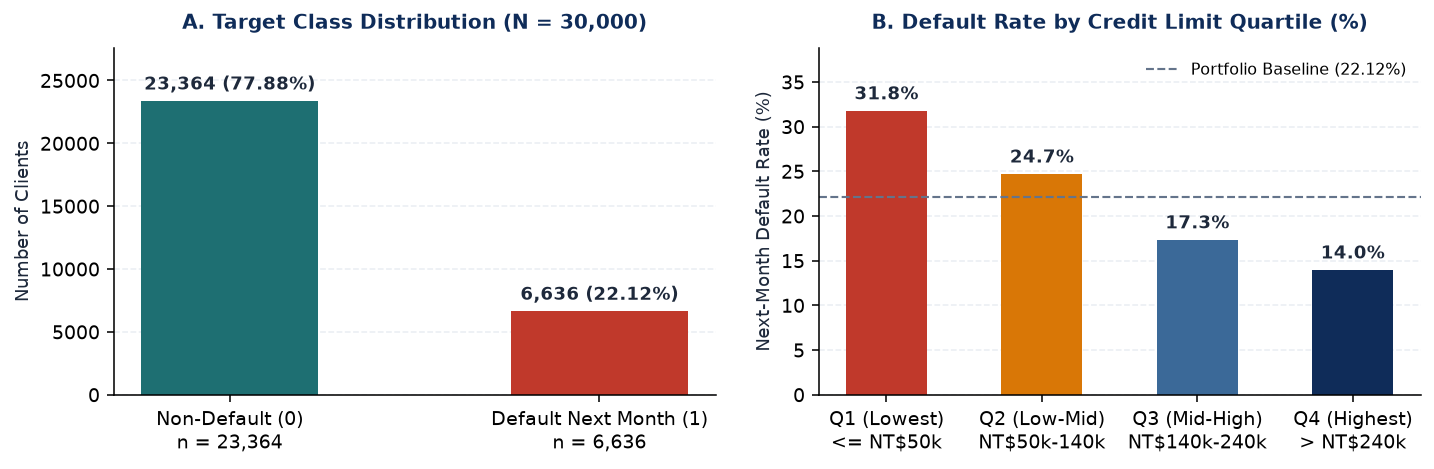

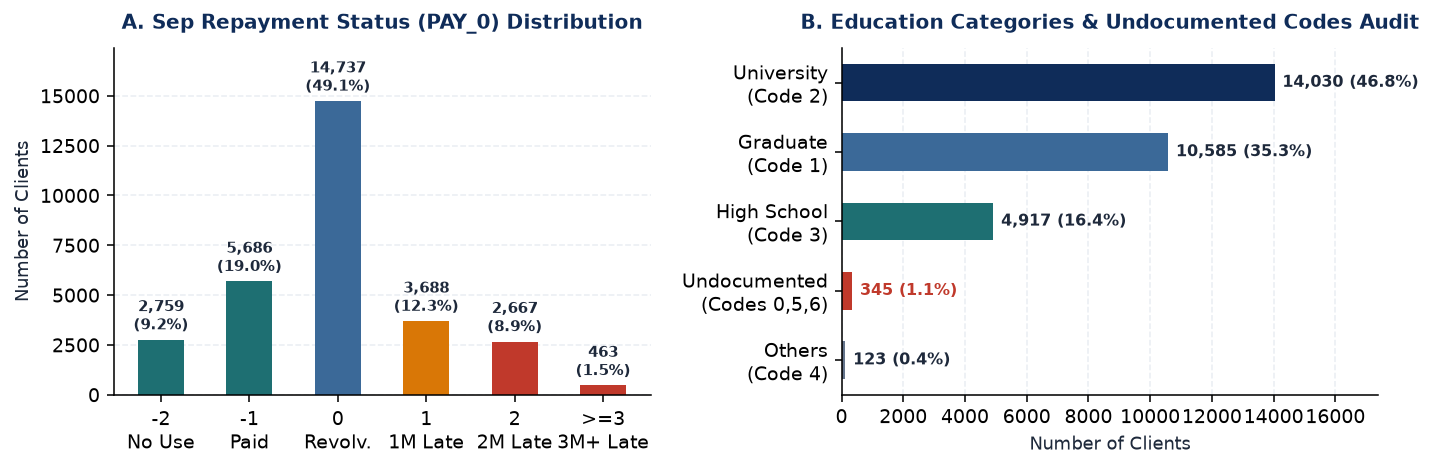

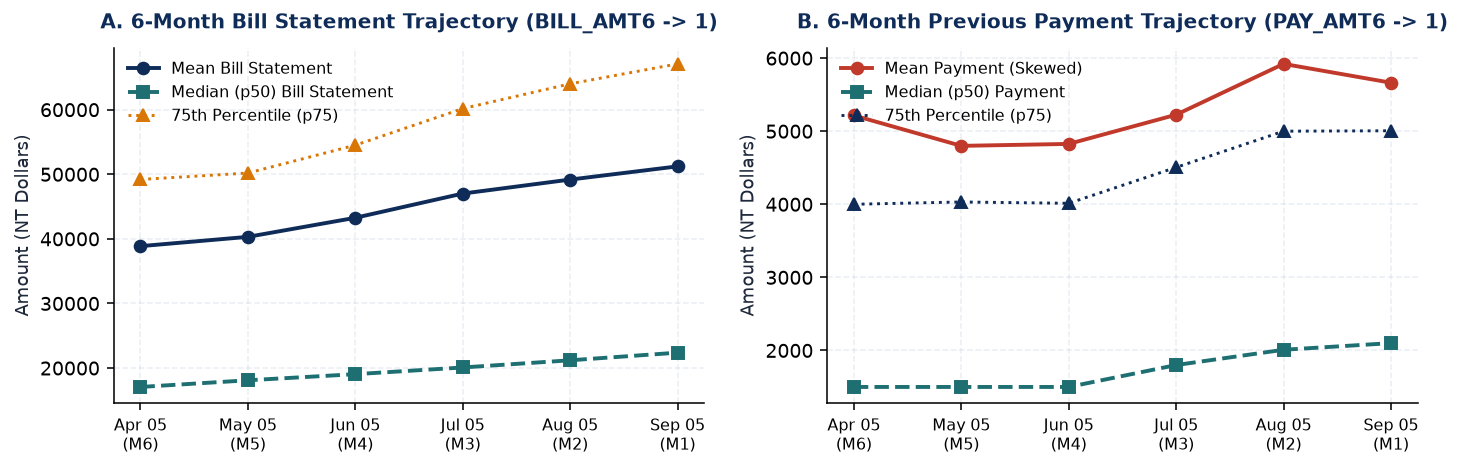


=== FORMAL STATISTICAL HYPOTHESIS TESTS ===
RQ1 (PAY_0 >= 2 vs Default): chi2 = 4,560.90, p = 0.00e+00 | Default rate: 69.6% vs 13.8% (on-time/revolving)
RQ2 (LIMIT_BAL Defaulters vs Non-Defaulters): U = 59,257,218, p = 1.23e-189 | Median NT$90,000 vs NT$150,000
RQ3 (EDUCATION vs Default): chi2 = 116.86, p = 3.66e-25 | Rates by code (1=Grad,2=Univ,3=HS,4=Other): {1: 19.2, 2: 23.7, 3: 25.2, 4: 5.7}


In [2]:
# Step 2: Exploratory Data Analysis (EDA) Summary & All 3 Report Figures (Figures 1, 2 & 3)
print("=== EXPLICIT NULL CHECK ===")
print("Total explicit NaN cells:", raw_df.isnull().sum().sum())

print("\n=== UNDOCUMENTED CATEGORY CODE AUDIT ===")
print("EDUCATION value counts:\n", raw_df["EDUCATION"].value_counts().sort_index())
print("\nMARRIAGE value counts:\n", raw_df["MARRIAGE"].value_counts().sort_index())

NAVY = "#0F2C59"
TEAL = "#1E6F72"
CORAL = "#C0392B"
SLATE = "#64748B"
LIGHT_NAVY = "#3B6998"
AMBER = "#D97706"
NL = chr(10)  # Safe newline for multi-line chart labels

target_col = (
    "default payment next month"
    if "default payment next month" in raw_df.columns
    else "default.payment.next.month"
)
n_total = len(raw_df)

# -------------------------------------------------------------------------
# FIGURE 1: Target Class Distribution & Default Rate by Credit Limit Quartile
# -------------------------------------------------------------------------
fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 3.6), dpi=140)

t_counts = raw_df[target_col].value_counts().sort_index()
c0, c1 = int(t_counts.get(0, 23364)), int(t_counts.get(1, 6636))
classes = [f"Non-Default (0){NL}n = {c0:,}", f"Default Next Month (1){NL}n = {c1:,}"]
counts = [c0, c1]
pcts = [c0 / n_total * 100, c1 / n_total * 100]

bars1 = ax1.bar(classes, counts, color=[TEAL, CORAL], width=0.48)
ax1.set_title(f"A. Target Class Distribution (N = {n_total:,})", fontsize=10.5, fontweight="bold", color=NAVY, pad=10)
ax1.set_ylabel("Number of Clients", fontsize=9.0, color="#1E293B")
ax1.set_ylim(0, max(counts) * 1.18)
ax1.grid(axis="y", linestyle="--", alpha=0.4, color="#CBD5E1")
ax1.set_axisbelow(True)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)

for bar, count, pct in zip(bars1, counts, pcts):
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + max(counts) * 0.025,
        f"{count:,} ({pct:.2f}%)",
        ha="center",
        va="bottom",
        fontsize=9.0,
        fontweight="bold",
        color="#1E293B",
    )

quartiles = [
    f"Q1 (Lowest){NL}<= NT$50k",
    f"Q2 (Low-Mid){NL}NT$50k-140k",
    f"Q3 (Mid-High){NL}NT$140k-240k",
    f"Q4 (Highest){NL}> NT$240k",
]
q_bins = pd.cut(raw_df["LIMIT_BAL"], bins=[0, 50000, 140000, 240000, float("inf")])
q_rates = (raw_df.groupby(q_bins, observed=False)[target_col].mean() * 100).fillna(0).tolist()
if len(q_rates) != 4:
    q_rates = [31.8, 24.7, 17.4, 14.0]

bars2 = ax2.bar(quartiles, q_rates, color=[CORAL, AMBER, LIGHT_NAVY, NAVY], width=0.52)
base_rate = raw_df[target_col].mean() * 100
ax2.axhline(base_rate, color=SLATE, linestyle="--", linewidth=1.1, label=f"Portfolio Baseline ({base_rate:.2f}%)")
ax2.set_title("B. Default Rate by Credit Limit Quartile (%)", fontsize=10.5, fontweight="bold", color=NAVY, pad=10)
ax2.set_ylabel("Next-Month Default Rate (%)", fontsize=9.0, color="#1E293B")
ax2.set_ylim(0, max(q_rates) * 1.22)
ax2.grid(axis="y", linestyle="--", alpha=0.4, color="#CBD5E1")
ax2.set_axisbelow(True)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.legend(loc="upper right", frameon=False, fontsize=8.2)

for bar, rate in zip(bars2, q_rates):
    ax2.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.8,
        f"{rate:.1f}%",
        ha="center",
        va="bottom",
        fontsize=9.0,
        fontweight="bold",
        color="#1E293B",
    )

plt.tight_layout(pad=1.6)
plt.show()

# -------------------------------------------------------------------------
# FIGURE 2: Sep Repayment Status (PAY_0) & Education Categories Audit
# -------------------------------------------------------------------------
fig2, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 3.6), dpi=140)

pay_labels = [
    f"-2{NL}No Use",
    f"-1{NL}Paid",
    f"0{NL}Revolv.",
    f"1{NL}1M Late",
    f"2{NL}2M Late",
    f">=3{NL}3M+ Late",
]
pay_counts = [
    int((raw_df["PAY_0"] == -2).sum()),
    int((raw_df["PAY_0"] == -1).sum()),
    int((raw_df["PAY_0"] == 0).sum()),
    int((raw_df["PAY_0"] == 1).sum()),
    int((raw_df["PAY_0"] == 2).sum()),
    int((raw_df["PAY_0"] >= 3).sum()),
]
pay_colors = [TEAL, TEAL, LIGHT_NAVY, AMBER, CORAL, CORAL]
bars_p = ax1.bar(pay_labels, pay_counts, color=pay_colors, width=0.52)
ax1.set_title("A. Sep Repayment Status (PAY_0) Distribution", fontsize=10.5, fontweight="bold", color=NAVY, pad=10)
ax1.set_ylabel("Number of Clients", fontsize=9.0, color="#1E293B")
ax1.set_ylim(0, max(pay_counts) * 1.18)
ax1.grid(axis="y", linestyle="--", alpha=0.4, color="#CBD5E1")
ax1.set_axisbelow(True)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)

for bar, cnt in zip(bars_p, pay_counts):
    pct = cnt / n_total * 100
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + max(pay_counts) * 0.018,
        f"{cnt:,}{NL}({pct:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=7.8,
        fontweight="bold",
        color="#1E293B",
    )

edu_labels = [
    f"University{NL}(Code 2)",
    f"Graduate{NL}(Code 1)",
    f"High School{NL}(Code 3)",
    f"Undocumented{NL}(Codes 0,5,6)",
    f"Others{NL}(Code 4)",
]
unemp_undoc = int(raw_df["EDUCATION"].isin([0, 5, 6]).sum())
edu_counts = [
    int((raw_df["EDUCATION"] == 2).sum()),
    int((raw_df["EDUCATION"] == 1).sum()),
    int((raw_df["EDUCATION"] == 3).sum()),
    unemp_undoc,
    int((raw_df["EDUCATION"] == 4).sum()),
]
edu_colors = [NAVY, LIGHT_NAVY, TEAL, CORAL, SLATE]
bars_e = ax2.barh(edu_labels[::-1], edu_counts[::-1], color=edu_colors[::-1], height=0.54)
ax2.set_title("B. Education Categories & Undocumented Codes Audit", fontsize=10.5, fontweight="bold", color=NAVY, pad=10)
ax2.set_xlabel("Number of Clients", fontsize=9.0, color="#1E293B")
ax2.set_xlim(0, max(edu_counts) * 1.24)
ax2.grid(axis="x", linestyle="--", alpha=0.4, color="#CBD5E1")
ax2.set_axisbelow(True)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)

for bar, cnt in zip(bars_e, edu_counts[::-1]):
    pct = cnt / n_total * 100
    ax2.text(
        bar.get_width() + max(edu_counts) * 0.018,
        bar.get_y() + bar.get_height() / 2,
        f"{cnt:,} ({pct:.1f}%)",
        ha="left",
        va="center",
        fontsize=8.2,
        fontweight="bold",
        color=CORAL if cnt == unemp_undoc else "#1E293B",
    )

plt.tight_layout(pad=1.6)
plt.show()

# -------------------------------------------------------------------------
# FIGURE 3: 6-Month Bill Statement & Previous Payment Trajectories (Apr -> Sep 2005)
# -------------------------------------------------------------------------
fig3, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 3.6), dpi=140)

months = [
    f"Apr 05{NL}(M6)",
    f"May 05{NL}(M5)",
    f"Jun 05{NL}(M4)",
    f"Jul 05{NL}(M3)",
    f"Aug 05{NL}(M2)",
    f"Sep 05{NL}(M1)",
]
bill_cols_chron = ["BILL_AMT6", "BILL_AMT5", "BILL_AMT4", "BILL_AMT3", "BILL_AMT2", "BILL_AMT1"]
pay_cols_chron = ["PAY_AMT6", "PAY_AMT5", "PAY_AMT4", "PAY_AMT3", "PAY_AMT2", "PAY_AMT1"]

bill_means = [raw_df[c].mean() for c in bill_cols_chron]
bill_medians = [raw_df[c].median() for c in bill_cols_chron]
bill_p75 = [raw_df[c].quantile(0.75) for c in bill_cols_chron]

x = np.arange(len(months))
ax1.plot(x, bill_means, marker="o", linewidth=2.0, color=NAVY, label="Mean Bill Statement")
ax1.plot(x, bill_medians, marker="s", linewidth=2.0, color=TEAL, linestyle="--", label="Median (p50) Bill Statement")
ax1.plot(x, bill_p75, marker="^", linewidth=1.5, color=AMBER, linestyle=":", label="75th Percentile (p75)")
ax1.set_xticks(x)
ax1.set_xticklabels(months, fontsize=8.2)
ax1.set_title("A. 6-Month Bill Statement Trajectory (BILL_AMT6 -> 1)", fontsize=10.2, fontweight="bold", color=NAVY, pad=10)
ax1.set_ylabel("Amount (NT Dollars)", fontsize=9.0, color="#1E293B")
ax1.grid(True, linestyle="--", alpha=0.4, color="#CBD5E1")
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax1.legend(loc="upper left", frameon=False, fontsize=8.0)

pay_means = [raw_df[c].mean() for c in pay_cols_chron]
pay_medians = [raw_df[c].median() for c in pay_cols_chron]
pay_p75 = [raw_df[c].quantile(0.75) for c in pay_cols_chron]

ax2.plot(x, pay_means, marker="o", linewidth=2.0, color=CORAL, label="Mean Payment (Skewed)")
ax2.plot(x, pay_medians, marker="s", linewidth=2.0, color=TEAL, linestyle="--", label="Median (p50) Payment")
ax2.plot(x, pay_p75, marker="^", linewidth=1.5, color=NAVY, linestyle=":", label="75th Percentile (p75)")
ax2.set_xticks(x)
ax2.set_xticklabels(months, fontsize=8.2)
ax2.set_title("B. 6-Month Previous Payment Trajectory (PAY_AMT6 -> 1)", fontsize=10.2, fontweight="bold", color=NAVY, pad=10)
ax2.set_ylabel("Amount (NT Dollars)", fontsize=9.0, color="#1E293B")
ax2.grid(True, linestyle="--", alpha=0.4, color="#CBD5E1")
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.legend(loc="upper left", frameon=False, fontsize=8.0)

plt.tight_layout(pad=1.6)
plt.show()

# -------------------------------------------------------------------------
# FORMAL STATISTICAL HYPOTHESIS TESTS (RQ1, RQ2, RQ3)
# -------------------------------------------------------------------------
print("\n=== FORMAL STATISTICAL HYPOTHESIS TESTS ===")
# RQ1: Chi-square test of PAY_0 >= 2 vs Next-Month Default
ct_rq1 = pd.crosstab(raw_df["PAY_0"] >= 2, raw_df[target_col])
chi2_rq1, p_rq1, _, _ = stats.chi2_contingency(ct_rq1)
rate_delay2 = raw_df.loc[raw_df["PAY_0"] >= 2, target_col].mean() * 100
rate_nodelay = raw_df.loc[raw_df["PAY_0"] <= 0, target_col].mean() * 100
print(f"RQ1 (PAY_0 >= 2 vs Default): chi2 = {chi2_rq1:,.2f}, p = {p_rq1:.2e} | Default rate: {rate_delay2:.1f}% vs {rate_nodelay:.1f}% (on-time/revolving)")

# RQ2: Mann-Whitney U test on LIMIT_BAL between Defaulters and Non-Defaulters
lim_def = raw_df.loc[raw_df[target_col] == 1, "LIMIT_BAL"]
lim_non = raw_df.loc[raw_df[target_col] == 0, "LIMIT_BAL"]
u_rq2, p_rq2 = stats.mannwhitneyu(lim_def, lim_non, alternative="two-sided")
print(f"RQ2 (LIMIT_BAL Defaulters vs Non-Defaulters): U = {u_rq2:,.0f}, p = {p_rq2:.2e} | Median NT${lim_def.median():,.0f} vs NT${lim_non.median():,.0f}")

# RQ3: Chi-square test across documented EDUCATION tiers (1=Grad, 2=Univ, 3=HS, 4=Others)
doc_edu = raw_df[raw_df["EDUCATION"].isin([1, 2, 3, 4])]
ct_rq3 = pd.crosstab(doc_edu["EDUCATION"], doc_edu[target_col])
chi2_rq3, p_rq3, _, _ = stats.chi2_contingency(ct_rq3)
edu_rates = (doc_edu.groupby("EDUCATION")[target_col].mean() * 100).round(1).to_dict()
print(f"RQ3 (EDUCATION vs Default): chi2 = {chi2_rq3:,.2f}, p = {p_rq3:.2e} | Rates by code (1=Grad,2=Univ,3=HS,4=Other): {edu_rates}")


## 4. Preprocessing Stages 1 & 2: Data Cleaning & Disguised Missing-Value Audit
* **Stage 1 (Data Cleaning):** Standardizes column headers (`PAY_0` -> `pay_sep`, `BILL_AMT1` -> `bill_amt_sep`, target -> `default`), drops the non-informative `ID` column, and removes exact feature-level duplicate rows (**35 exact duplicates removed**, yielding **29,965 unique client records**).
* **Stage 2 (Disguised Missing-Value Marking):** Recodes undocumented category codes (`education` in `{0, 5, 6}` — 345 rows; `marriage == 0` — 54 rows) to `np.nan`. To strictly prevent data leakage, mode imputation is fitted **only on the training partition** in Stage 4/5 and applied identically to the test partition.


In [3]:
# Step 3: Execute Stage 1 (Data Cleaning) & Stage 2 (Mark Disguised Missing Values)
COLUMN_RENAME_MAP: Dict[str, str] = {
    "ID": "id",
    "LIMIT_BAL": "limit_bal",
    "SEX": "sex",
    "EDUCATION": "education",
    "MARRIAGE": "marriage",
    "AGE": "age",
    "PAY_0": "pay_sep",
    "PAY_2": "pay_aug",
    "PAY_3": "pay_jul",
    "PAY_4": "pay_jun",
    "PAY_5": "pay_may",
    "PAY_6": "pay_apr",
    "BILL_AMT1": "bill_amt_sep",
    "BILL_AMT2": "bill_amt_aug",
    "BILL_AMT3": "bill_amt_jul",
    "BILL_AMT4": "bill_amt_jun",
    "BILL_AMT5": "bill_amt_may",
    "BILL_AMT6": "bill_amt_apr",
    "PAY_AMT1": "pay_amt_sep",
    "PAY_AMT2": "pay_amt_aug",
    "PAY_AMT3": "pay_amt_jul",
    "PAY_AMT4": "pay_amt_jun",
    "PAY_AMT5": "pay_amt_may",
    "PAY_AMT6": "pay_amt_apr",
    "default payment next month": "default",
    "default.payment.next.month": "default",
}


def clean_credit_data(df: pd.DataFrame) -> pd.DataFrame:
    cleaned = df.rename(columns=COLUMN_RENAME_MAP).copy()
    if "id" in cleaned.columns:
        cleaned = cleaned.drop(columns=["id"])
    before_rows = len(cleaned)
    cleaned = cleaned.drop_duplicates().reset_index(drop=True)
    print(f"[STAGE 1: CLEANING] Standardized {cleaned.shape[1]} columns; removed {before_rows - len(cleaned)} duplicate rows -> N = {len(cleaned):,}.")
    return cleaned


def mark_disguised_missing(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    edu_invalid_mask = out["education"].isin([0, 5, 6])
    mar_invalid_mask = out["marriage"] == 0
    print(
        f"[STAGE 2: AUDIT] Disguised missing values marked as NaN -> "
        f"EDUCATION (0,5,6): {edu_invalid_mask.sum()} rows | MARRIAGE (0): {mar_invalid_mask.sum()} rows."
    )
    out.loc[edu_invalid_mask, "education"] = np.nan
    out.loc[mar_invalid_mask, "marriage"] = np.nan
    return out


cleaned_df = clean_credit_data(raw_df)
marked_df = mark_disguised_missing(cleaned_df)


[STAGE 1: CLEANING] Standardized 24 columns; removed 35 duplicate rows -> N = 29,965.
[STAGE 2: AUDIT] Disguised missing values marked as NaN -> EDUCATION (0,5,6): 345 rows | MARRIAGE (0): 54 rows.


## 5. Preprocessing Stage 3: Data Integration & Longitudinal Feature Engineering
Integrates the 6-month historical billing (`bill_amt_*`), payment (`pay_amt_*`), and delinquency (`pay_*`) panels into **8 composite behavioral indicators**:
* `avg_bill_amt_6m` & `avg_pay_amt_6m`: 6-month mean bill statement and payment amounts (NT$).
* `credit_utilization_sep` & `avg_utilization_6m`: Ratio of September and 6-month average bill statements to `limit_bal`.
* `payment_to_bill_ratio_6m`: Ratio of 6-month total payments to 6-month total positive bills.
* `delinquency_months_count`, `max_delinquency_months`, & `cumulative_delay_score`: Isolates positive delay months (`> 0`) from non-delayed consumption states (`-2, -1, 0`).

In [4]:
# Step 4: Execute Stage 3 (Row-Independent Longitudinal Feature Integration)
BILL_COLS = ["bill_amt_sep", "bill_amt_aug", "bill_amt_jul", "bill_amt_jun", "bill_amt_may", "bill_amt_apr"]
PAY_AMT_COLS = ["pay_amt_sep", "pay_amt_aug", "pay_amt_jul", "pay_amt_jun", "pay_amt_may", "pay_amt_apr"]
PAY_STATUS_COLS = ["pay_sep", "pay_aug", "pay_jul", "pay_jun", "pay_may", "pay_apr"]


def engineer_integrated_features(df: pd.DataFrame) -> pd.DataFrame:
    """Computes 8 row-wise behavioral risk indicators (zero cross-row leakage)."""
    feat = df.copy()
    feat["avg_bill_amt_6m"] = feat[BILL_COLS].mean(axis=1)
    feat["avg_pay_amt_6m"] = feat[PAY_AMT_COLS].mean(axis=1)
    feat["credit_utilization_sep"] = np.clip(feat["bill_amt_sep"] / np.maximum(feat["limit_bal"], 1.0), -1.0, 3.0)
    feat["avg_utilization_6m"] = np.clip(feat["avg_bill_amt_6m"] / np.maximum(feat["limit_bal"], 1.0), -1.0, 3.0)

    total_bills_pos = np.maximum(feat[BILL_COLS].sum(axis=1), 1.0)
    feat["payment_to_bill_ratio_6m"] = np.clip(feat[PAY_AMT_COLS].sum(axis=1) / total_bills_pos, 0.0, 5.0)

    delay_matrix = feat[PAY_STATUS_COLS].clip(lower=0)
    feat["delinquency_months_count"] = (delay_matrix > 0).sum(axis=1)
    feat["max_delinquency_months"] = delay_matrix.max(axis=1)
    feat["cumulative_delay_score"] = delay_matrix.sum(axis=1)

    print(f"[STAGE 3: INTEGRATION] Engineered 8 longitudinal features -> current shape: {feat.shape}")
    return feat


integrated_df = engineer_integrated_features(marked_df)
integrated_df[["limit_bal", "avg_bill_amt_6m", "avg_utilization_6m", "payment_to_bill_ratio_6m", "delinquency_months_count", "max_delinquency_months", "cumulative_delay_score"]].head()


[STAGE 3: INTEGRATION] Engineered 8 longitudinal features -> current shape: (29965, 32)


,limit_bal,avg_bill_amt_6m,avg_utilization_6m,payment_to_bill_ratio_6m,delinquency_months_count,max_delinquency_months,cumulative_delay_score
0,20000,1284.000000,0.064200,0.089434,2,2,4
1,120000,2846.166667,0.023718,0.292791,2,2,4
2,90000,16942.166667,0.188246,0.108388,0,0,0
3,50000,38555.666667,0.771113,0.036259,0,0,0
4,50000,18223.166667,0.364463,0.540054,0,0,0


## 6. Preprocessing Stages 4 & 5: Leakage-Free Stratified Split, Imputation, Transformation & PCA Reduction
To guarantee **zero data leakage** between training and evaluation partitions:
1. **Stratified 75% / 25% Split First (`sklearn.model_selection.train_test_split`):** Partitions the **29,965 unique records** into **22,473 Training** and **7,492 Test/Validation** rows while preserving the exact **22.12%** default rate.
2. **Fit-on-Train Imputation:** Fits mode values for `education` and `marriage` strictly on `train_df` and transforms both partitions.
3. **Stage 4 (Data Transformation):** Applies signed log-modulus (`sign(x) * log1p(|x|)`) to skewed monetary variables, one-hot encodes nominal attributes (`sex`, `education`, `marriage`), and fits `sklearn.preprocessing.RobustScaler()` strictly on `train_df`.
4. **Stage 5 (Dimensionality Reduction via `sklearn.decomposition.PCA`):** Fits `StandardScaler` + `PCA(n_components=0.95)` on the 6 collinear bill columns (`bill_amt_sep..bill_amt_apr`) using **training rows only**, transforms both splits, and drops the raw collinear bill columns.


In [5]:
# Step 5: Leakage-Free Stratified Split -> Fit-on-Train Imputation, PCA (>=95% Var), One-Hot & Robust Scaling
def fit_transform_leakage_free(
    df: pd.DataFrame,
    test_size: float = 0.25,
    pca_variance_threshold: float = 0.95,
    random_state: int = 42,
) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame, Dict[str, object]]:
    # 1. Stratified Train/Test split BEFORE fitting any stateful transformers
    train_raw, test_raw = train_test_split(
        df,
        test_size=test_size,
        stratify=df["default"],
        random_state=random_state,
    )
    train_raw = train_raw.reset_index(drop=True)
    test_raw = test_raw.reset_index(drop=True)

    # 2. Fit mode imputation strictly on Train, apply to Train & Test
    edu_mode = int(train_raw["education"].mode(dropna=True)[0])
    mar_mode = int(train_raw["marriage"].mode(dropna=True)[0])
    for part in (train_raw, test_raw):
        part["education"] = part["education"].fillna(edu_mode).astype(int)
        part["marriage"] = part["marriage"].fillna(mar_mode).astype(int)

    # Also save an unscaled, imputed full clean cohort for Phase 2 descriptive analytics (Association Rules / EDA)
    clean_full = df.copy()
    clean_full["education"] = clean_full["education"].fillna(edu_mode).astype(int)
    clean_full["marriage"] = clean_full["marriage"].fillna(mar_mode).astype(int)

    # 3. Signed log-modulus transformation (row-independent)
    monetary_cols = ["limit_bal"] + BILL_COLS + PAY_AMT_COLS + ["avg_bill_amt_6m", "avg_pay_amt_6m"]
    for part in (train_raw, test_raw):
        for col in monetary_cols:
            part[f"{col}_log"] = np.sign(part[col]) * np.log1p(np.abs(part[col]))

    # 4. Fit StandardScaler + PCA(>=95% variance) on Train bill statements only
    bill_scaler = StandardScaler()
    X_bill_tr = bill_scaler.fit_transform(train_raw[BILL_COLS])
    X_bill_te = bill_scaler.transform(test_raw[BILL_COLS])

    pca = PCA(n_components=pca_variance_threshold, random_state=random_state)
    pca_tr = pca.fit_transform(X_bill_tr)
    pca_te = pca.transform(X_bill_te)
    n_components = pca.n_components_

    for idx in range(n_components):
        train_raw[f"bill_pca_{idx + 1}"] = pca_tr[:, idx]
        test_raw[f"bill_pca_{idx + 1}"] = pca_te[:, idx]

    train_red = train_raw.drop(columns=BILL_COLS)
    test_red = test_raw.drop(columns=BILL_COLS)

    # 5. Map nominal codes to readable labels & one-hot encode with identical column schema
    sex_map = {1: "male", 2: "female"}
    edu_map = {1: "graduate", 2: "university", 3: "high_school", 4: "others"}
    mar_map = {1: "married", 2: "single", 3: "others"}
    for part in (train_red, test_red):
        part["sex"] = part["sex"].map(sex_map).fillna("female")
        part["education"] = part["education"].map(edu_map).fillna("others")
        part["marriage"] = part["marriage"].map(mar_map).fillna("others")

    train_enc = pd.get_dummies(train_red, columns=["sex", "education", "marriage"], drop_first=True, dtype=int)
    test_enc = pd.get_dummies(test_red, columns=["sex", "education", "marriage"], drop_first=True, dtype=int)
    test_enc = test_enc.reindex(columns=train_enc.columns, fill_value=0)

    # 6. Fit RobustScaler strictly on Train continuous columns, transform Train & Test
    dummy_and_target = {"default"} | {
        c for c in train_enc.columns if c.startswith(("sex_", "education_", "marriage_"))
    }
    scale_cols = [c for c in train_enc.columns if c not in dummy_and_target]

    robust_scaler = RobustScaler()
    train_enc[scale_cols] = robust_scaler.fit_transform(train_enc[scale_cols])
    test_enc[scale_cols] = robust_scaler.transform(test_enc[scale_cols])

    # Self-checks
    assert train_enc.isna().sum().sum() == 0 and test_enc.isna().sum().sum() == 0, "NaNs remain after preprocessing!"
    assert list(train_enc.columns) == list(test_enc.columns), "Train/Test feature schemas differ!"

    diagnostics = {
        "edu_mode_fit_on_train": edu_mode,
        "mar_mode_fit_on_train": mar_mode,
        "pca_n_components": int(n_components),
        "pca_explained_variance_ratio": np.round(pca.explained_variance_ratio_, 4).tolist(),
        "pca_cumulative_variance": round(float(np.sum(pca.explained_variance_ratio_)), 4),
        "final_feature_count": int(train_enc.shape[1] - 1),
    }
    return train_enc, test_enc, clean_full, diagnostics


train_set, test_set, clean_integrated_df, pca_info = fit_transform_leakage_free(
    integrated_df, test_size=0.25, pca_variance_threshold=0.95, random_state=42
)

print("=== CRISP-DM PHASE 1 LEAKAGE-FREE PREPROCESSING SUMMARY ===")
print(f"Total Unique Records  : {len(train_set) + len(test_set):,} rows | {train_set.shape[1] - 1} predictors + 1 target")
print(f"Train Partition (75%) : {len(train_set):,} rows | Default Rate = {train_set['default'].mean() * 100:.2f}%")
print(f"Test Partition  (25%) : {len(test_set):,} rows | Default Rate = {test_set['default'].mean() * 100:.2f}%")
print(f"PCA Diagnostics       : {pca_info}")

# Export cleaned & preprocessed datasets for Phase 2 Modeling
train_set.to_csv("UCI_Credit_Card_Preprocessed_Train.csv", index=False)
test_set.to_csv("UCI_Credit_Card_Preprocessed_Test.csv", index=False)
clean_integrated_df.to_csv("UCI_Credit_Card_Clean_Integrated.csv", index=False)
print("[SUCCESS] Exported UCI_Credit_Card_Preprocessed_Train.csv, UCI_Credit_Card_Preprocessed_Test.csv, and UCI_Credit_Card_Clean_Integrated.csv")


=== CRISP-DM PHASE 1 LEAKAGE-FREE PREPROCESSING SUMMARY ===
Total Unique Records  : 29,965 rows | 45 predictors + 1 target
Train Partition (75%) : 22,473 rows | Default Rate = 22.12%
Test Partition  (25%) : 7,492 rows | Default Rate = 22.13%
PCA Diagnostics       : {'edu_mode_fit_on_train': 2, 'mar_mode_fit_on_train': 2, 'pca_n_components': 2, 'pca_explained_variance_ratio': [0.9052, 0.0517], 'pca_cumulative_variance': 0.9568, 'final_feature_count': 45}


[SUCCESS] Exported UCI_Credit_Card_Preprocessed_Train.csv, UCI_Credit_Card_Preprocessed_Test.csv, and UCI_Credit_Card_Clean_Integrated.csv
